In [36]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [37]:
# read in the file
words = open('names.txt', 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [38]:
# build the mapping from char to index and vice versa
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [39]:
# build the dataset

block_size = 3 # context length: how many previous chars we take to predict the next char
X, Y = [], [] # X contains the context and Y contains the supposed output in dataset

for word in words[:5]:

    print(word)
    context = [0] * block_size # [0, 0, ..., 0] with length of block_size
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        print(''.join(itos[i] for i in context), '------>', itos[ix])
        context = context[1:] + [ix] # crop and append

X = torch.tensor(X) # 2d tensor
Y = torch.tensor(Y) # 1d tensor

emma
... ------> e
..e ------> m
.em ------> m
emm ------> a
mma ------> .
olivia
... ------> o
..o ------> l
.ol ------> i
oli ------> v
liv ------> i
ivi ------> a
via ------> .
ava
... ------> a
..a ------> v
.av ------> a
ava ------> .
isabella
... ------> i
..i ------> s
.is ------> a
isa ------> b
sab ------> e
abe ------> l
bel ------> l
ell ------> a
lla ------> .
sophia
... ------> s
..s ------> o
.so ------> p
sop ------> h
oph ------> i
phi ------> a
hia ------> .


In [40]:
X, Y

(tensor([[ 0,  0,  0],
         [ 0,  0,  5],
         [ 0,  5, 13],
         [ 5, 13, 13],
         [13, 13,  1],
         [ 0,  0,  0],
         [ 0,  0, 15],
         [ 0, 15, 12],
         [15, 12,  9],
         [12,  9, 22],
         [ 9, 22,  9],
         [22,  9,  1],
         [ 0,  0,  0],
         [ 0,  0,  1],
         [ 0,  1, 22],
         [ 1, 22,  1],
         [ 0,  0,  0],
         [ 0,  0,  9],
         [ 0,  9, 19],
         [ 9, 19,  1],
         [19,  1,  2],
         [ 1,  2,  5],
         [ 2,  5, 12],
         [ 5, 12, 12],
         [12, 12,  1],
         [ 0,  0,  0],
         [ 0,  0, 19],
         [ 0, 19, 15],
         [19, 15, 16],
         [15, 16,  8],
         [16,  8,  9],
         [ 8,  9,  1]]),
 tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
          1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0]))

In [41]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

In [42]:
C = torch.randn((27, 2)) # each 27 chars will have 2d embedding


In [43]:
C[5]

tensor([1.3151, 1.4951])

In [44]:
F.one_hot(torch.tensor(5), num_classes = 27).float() @ C 
# since this is more complex that the index way, we discard this method

tensor([1.3151, 1.4951])

In [45]:
emb = C[X]
emb

tensor([[[-1.4588, -1.3739],
         [-1.4588, -1.3739],
         [-1.4588, -1.3739]],

        [[-1.4588, -1.3739],
         [-1.4588, -1.3739],
         [ 1.3151,  1.4951]],

        [[-1.4588, -1.3739],
         [ 1.3151,  1.4951],
         [-0.4542, -0.7778]],

        [[ 1.3151,  1.4951],
         [-0.4542, -0.7778],
         [-0.4542, -0.7778]],

        [[-0.4542, -0.7778],
         [-0.4542, -0.7778],
         [ 1.0866, -1.1978]],

        [[-1.4588, -1.3739],
         [-1.4588, -1.3739],
         [-1.4588, -1.3739]],

        [[-1.4588, -1.3739],
         [-1.4588, -1.3739],
         [-0.2297, -0.2228]],

        [[-1.4588, -1.3739],
         [-0.2297, -0.2228],
         [ 0.1766,  0.6448]],

        [[-0.2297, -0.2228],
         [ 0.1766,  0.6448],
         [-1.6773,  0.0361]],

        [[ 0.1766,  0.6448],
         [-1.6773,  0.0361],
         [ 0.5164,  0.1168]],

        [[-1.6773,  0.0361],
         [ 0.5164,  0.1168],
         [-1.6773,  0.0361]],

        [[ 0.5164,  0

In [46]:
C[X].shape

torch.Size([32, 3, 2])

In [47]:
C[X[13, 2]]

tensor([ 1.0866, -1.1978])

In [48]:
C[X][13, 2]

tensor([ 1.0866, -1.1978])

In [49]:
W1 = torch.randn((6, 100)) # it is 6 since 6 = 3*2
b1 = torch.randn(100)

In [50]:
emb[:, 0, :]
emb[:, 1, :]
emb[:, 2, :]

tensor([[-1.4588, -1.3739],
        [ 1.3151,  1.4951],
        [-0.4542, -0.7778],
        [-0.4542, -0.7778],
        [ 1.0866, -1.1978],
        [-1.4588, -1.3739],
        [-0.2297, -0.2228],
        [ 0.1766,  0.6448],
        [-1.6773,  0.0361],
        [ 0.5164,  0.1168],
        [-1.6773,  0.0361],
        [ 1.0866, -1.1978],
        [-1.4588, -1.3739],
        [ 1.0866, -1.1978],
        [ 0.5164,  0.1168],
        [ 1.0866, -1.1978],
        [-1.4588, -1.3739],
        [-1.6773,  0.0361],
        [-0.3003, -0.3674],
        [ 1.0866, -1.1978],
        [-0.6938, -0.9464],
        [ 1.3151,  1.4951],
        [ 0.1766,  0.6448],
        [ 0.1766,  0.6448],
        [ 1.0866, -1.1978],
        [-1.4588, -1.3739],
        [-0.3003, -0.3674],
        [-0.2297, -0.2228],
        [ 1.6027,  0.6671],
        [-0.6107, -0.9928],
        [-1.6773,  0.0361],
        [ 1.0866, -1.1978]])

In [51]:
torch.cat((emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]), 1) 
# this only works with a context size of 3


tensor([[-1.4588, -1.3739, -1.4588, -1.3739, -1.4588, -1.3739],
        [-1.4588, -1.3739, -1.4588, -1.3739,  1.3151,  1.4951],
        [-1.4588, -1.3739,  1.3151,  1.4951, -0.4542, -0.7778],
        [ 1.3151,  1.4951, -0.4542, -0.7778, -0.4542, -0.7778],
        [-0.4542, -0.7778, -0.4542, -0.7778,  1.0866, -1.1978],
        [-1.4588, -1.3739, -1.4588, -1.3739, -1.4588, -1.3739],
        [-1.4588, -1.3739, -1.4588, -1.3739, -0.2297, -0.2228],
        [-1.4588, -1.3739, -0.2297, -0.2228,  0.1766,  0.6448],
        [-0.2297, -0.2228,  0.1766,  0.6448, -1.6773,  0.0361],
        [ 0.1766,  0.6448, -1.6773,  0.0361,  0.5164,  0.1168],
        [-1.6773,  0.0361,  0.5164,  0.1168, -1.6773,  0.0361],
        [ 0.5164,  0.1168, -1.6773,  0.0361,  1.0866, -1.1978],
        [-1.4588, -1.3739, -1.4588, -1.3739, -1.4588, -1.3739],
        [-1.4588, -1.3739, -1.4588, -1.3739,  1.0866, -1.1978],
        [-1.4588, -1.3739,  1.0866, -1.1978,  0.5164,  0.1168],
        [ 1.0866, -1.1978,  0.5164,  0.1

In [52]:
torch.cat(torch.unbind(emb, 1), 1).shape
# work regardless of the context size

torch.Size([32, 6])

In [53]:
emb.view(32, 6)

tensor([[-1.4588, -1.3739, -1.4588, -1.3739, -1.4588, -1.3739],
        [-1.4588, -1.3739, -1.4588, -1.3739,  1.3151,  1.4951],
        [-1.4588, -1.3739,  1.3151,  1.4951, -0.4542, -0.7778],
        [ 1.3151,  1.4951, -0.4542, -0.7778, -0.4542, -0.7778],
        [-0.4542, -0.7778, -0.4542, -0.7778,  1.0866, -1.1978],
        [-1.4588, -1.3739, -1.4588, -1.3739, -1.4588, -1.3739],
        [-1.4588, -1.3739, -1.4588, -1.3739, -0.2297, -0.2228],
        [-1.4588, -1.3739, -0.2297, -0.2228,  0.1766,  0.6448],
        [-0.2297, -0.2228,  0.1766,  0.6448, -1.6773,  0.0361],
        [ 0.1766,  0.6448, -1.6773,  0.0361,  0.5164,  0.1168],
        [-1.6773,  0.0361,  0.5164,  0.1168, -1.6773,  0.0361],
        [ 0.5164,  0.1168, -1.6773,  0.0361,  1.0866, -1.1978],
        [-1.4588, -1.3739, -1.4588, -1.3739, -1.4588, -1.3739],
        [-1.4588, -1.3739, -1.4588, -1.3739,  1.0866, -1.1978],
        [-1.4588, -1.3739,  1.0866, -1.1978,  0.5164,  0.1168],
        [ 1.0866, -1.1978,  0.5164,  0.1

In [54]:
emb.view(32, 6) == torch.cat(torch.unbind(emb, 1), 1)

tensor([[True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, T

In [55]:
# h = emb.view(32, 6) @ W1 + b1
# h = emb.view(emb.shape[0], 6) @ W1 + b1 
# the line above does not need one to hard code 32
h = emb.view(-1, 6) @ W1 + b1 # letting torch figure the size itself by -1

In [56]:
h.shape

torch.Size([32, 100])

In [57]:
h = h.tanh()
h

tensor([[ 1.0000,  0.9851,  0.5114,  ...,  0.7022, -0.6643, -0.5541],
        [ 1.0000,  0.9859,  0.9818,  ..., -0.9988, -0.9985,  0.9995],
        [ 0.8079,  0.9999,  0.9228,  ..., -0.7037, -0.4092,  0.9937],
        ...,
        [-0.9795,  0.9610, -0.1342,  ...,  0.2831,  0.8777, -0.3431],
        [-0.9771, -0.5045, -0.9968,  ...,  0.9638,  0.9992, -0.9999],
        [ 0.9988,  0.9509,  0.9700,  ...,  0.1436, -0.9752,  0.9978]])

In [58]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)
W2, b2, W2.shape, b2.shape

(tensor([[ 0.9818, -0.1715,  0.0768,  ...,  1.2166,  0.1923, -0.1353],
         [-0.8844,  0.7199,  0.4152,  ..., -0.2297,  1.0425, -0.0175],
         [-0.3363, -2.1183, -1.6498,  ...,  0.1095,  0.2751,  0.1972],
         ...,
         [-0.8354, -0.0715, -0.1380,  ..., -0.0419,  0.6092,  1.1189],
         [-0.2874, -1.0178,  0.5164,  ..., -0.4277,  2.4508,  0.1538],
         [ 0.1983, -0.6630,  1.4691,  ...,  0.7924,  0.3079,  1.6380]]),
 tensor([ 0.6190,  1.0790,  0.4155,  0.1261,  1.3400,  0.5607,  0.9042,  0.9657,
         -0.1297, -0.3592,  0.6242,  0.2866,  0.4751,  0.3922,  0.9032,  2.2491,
          0.3667,  0.2525, -1.1274, -0.0860, -0.7017, -1.2014,  1.5426,  3.2411,
         -0.3622,  0.7197,  1.1574]),
 torch.Size([100, 27]),
 torch.Size([27]))

In [59]:
logits = h @ W2 + b2
logits

tensor([[-2.2752e-01, -4.7436e+00,  8.2763e+00,  4.8631e-01,  1.5178e+01,
          5.3866e-02, -9.7097e-01,  8.0282e+00, -1.0648e+01, -2.4833e+00,
          7.7752e+00, -5.3370e+00,  1.5034e+00,  9.0477e+00,  1.8364e-01,
          6.7516e+00, -1.4594e+01, -9.3929e+00,  5.2491e+00,  3.6583e+00,
         -5.8357e+00,  6.0849e+00, -1.2210e+01, -1.1259e-01, -4.3415e+00,
         -2.8009e+00,  5.2791e+00],
        [ 6.5032e+00,  8.0208e+00,  3.2506e+00, -2.8787e-01, -2.7648e-01,
          6.0172e+00,  9.1747e+00,  3.0941e+01, -8.9026e+00,  1.0989e+00,
         -9.8584e+00,  1.6548e+00,  4.1812e+00,  1.4551e+01,  9.7052e+00,
          1.6797e+01, -2.3233e+01,  4.8761e+00, -2.4688e-01, -3.5808e+00,
         -1.7104e+00,  4.7240e-01,  4.4750e+00, -5.0940e+00,  6.3288e+00,
         -5.9924e+00,  3.6264e-01],
        [-8.1227e+00, -6.2230e+00,  1.3177e+01,  3.5758e+00,  4.2235e+00,
         -4.4787e-01, -5.1908e-01, -2.6209e+01, -1.6761e+01, -1.2100e+01,
          2.5193e+00, -2.4841e+00,  1.23

In [60]:
# obtaining counts adn then probabilities
counts = logits.exp() 
probs = counts / counts.sum(1, keepdims = True)
probs, probs.shape

(tensor([[2.0295e-07, 2.2187e-09, 1.0013e-03, 4.1439e-07, 9.9500e-01, 2.6890e-07,
          9.6498e-08, 7.8131e-04, 6.0519e-12, 2.1268e-08, 6.0664e-04, 1.2256e-09,
          1.1458e-06, 2.1655e-03, 3.0617e-07, 2.1796e-04, 1.1695e-13, 2.1229e-11,
          4.8513e-05, 9.8850e-06, 7.4437e-10, 1.1191e-04, 1.2690e-12, 2.2767e-07,
          3.3169e-09, 1.5480e-08, 4.9990e-05],
         [2.4360e-11, 1.1112e-10, 9.4210e-13, 2.7375e-14, 2.7689e-14, 1.4983e-11,
          3.5231e-10, 1.0000e+00, 4.9661e-18, 1.0955e-13, 1.9096e-18, 1.9101e-13,
          2.3891e-12, 7.6149e-08, 5.9883e-10, 7.1950e-07, 2.9664e-24, 4.7868e-12,
          2.8521e-14, 1.0168e-15, 6.5999e-15, 5.8552e-14, 3.2052e-12, 2.2391e-16,
          2.0461e-11, 9.1186e-17, 5.2465e-14],
         [5.6136e-10, 3.7521e-09, 9.9891e-01, 6.7582e-05, 1.2916e-04, 1.2089e-06,
          1.1258e-06, 7.8438e-18, 9.9498e-14, 1.0513e-11, 2.3496e-05, 1.5778e-07,
          6.4972e-06, 3.0857e-05, 5.4114e-07, 8.9984e-11, 1.3892e-11, 4.1208e-06,
    

In [61]:
probs[torch.arange(32), Y] # the probablity of the "correct" prediction

tensor([2.6890e-07, 7.6149e-08, 3.0857e-05, 1.3270e-08, 4.2531e-07, 2.1796e-04,
        2.4664e-06, 4.7049e-05, 3.3342e-17, 1.4454e-08, 1.7198e-12, 8.6229e-10,
        2.2187e-09, 2.0522e-10, 6.2889e-05, 1.5828e-08, 2.1268e-08, 3.8639e-06,
        3.5832e-11, 9.9868e-01, 1.5757e-11, 5.9231e-11, 2.8111e-04, 7.4655e-06,
        5.0137e-09, 9.8850e-06, 2.0794e-02, 1.7739e-13, 1.4788e-09, 2.3889e-07,
        2.0827e-08, 1.9948e-09])

In [62]:
loss = -probs[torch.arange(32), Y].log().mean()
loss

tensor(16.8625)

In [63]:
# ------------ cluster together --------------- #

In [64]:
X.shape, Y.shape

(torch.Size([32, 3]), torch.Size([32]))

In [65]:
g = torch.Generator().manual_seed(2147483647)
c = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator = g)
W2 = torch.randn((100, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
n_para

3481

In [66]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32 * 100
logits = h @ W2 + b2 # 32 * 27
# counts = logits.exp()
# probs = counts / counts.sum(1, keepdims=True)
# loss = - probs[torch.arange(32), Y].log().mean()
# the three lines above can be encapsulated into one line with the built-in
# torch library: 
loss = F.cross_entropy(logits, Y)
# this line is not only more precise, but also create less memory loss, and 
# reduce the number of backward pass that the computer needs to finish since 
# all the operations are clustered
# it also prevents extreme value from overflowing the computer by subtracting 
# the maximum entry in the logits from each entry
loss

tensor(16.5296)

In [67]:
for p in parameters:
    p.requires_grad = True

In [72]:
for _ in range(1000):
    # forward pass
    emb = C[X]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y)
    print(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data -= 0.1 * p.grad

0.30954474210739136
0.3088409900665283
0.30815261602401733
0.3074789047241211
0.3068196177482605
0.30617430806159973
0.3055424392223358
0.30492377281188965
0.3043178617954254
0.3037243187427521
0.30314284563064575
0.30257314443588257
0.3020147383213043
0.3014674484729767
0.300930917263031
0.3004048466682434
0.2998889982700348
0.2993829548358917
0.29888665676116943
0.2983996272087097
0.2979218065738678
0.2974528670310974
0.29699257016181946
0.2965407371520996
0.2960970401763916
0.29566138982772827
0.2952335774898529
0.2948133647441864
0.29440051317214966
0.2939949035644531
0.2935963273048401
0.2932046055793762
0.29281964898109436
0.29244112968444824
0.2920690178871155
0.2917031943798065
0.29134342074394226
0.29098957777023315
0.29064151644706726
0.2902991473674774
0.2899622619152069
0.28963083028793335
0.28930461406707764
0.288983553647995
0.28866758942604065
0.2883565127849579
0.28805017471313477
0.28774863481521606
0.28745168447494507
0.2871592342853546
0.286871075630188
0.28658738732

In [ ]:
# for now the loss function is very low since there is only 32 examples to 
# fit and it is obviously overfitting, leading to a very low loss. 

tensor(19.2080)

In [ ]:
# ____Processing the whole data set instead of just the first 5 words

In [75]:
block_size = 3 
X, Y = [], [] 
for word in words:
    # print(word)
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '------>', itos[ix])
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y)

In [76]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [86]:
g = torch.Generator().manual_seed(2147483647)
c = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator = g)
W2 = torch.randn((100, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
n_para

3481

In [87]:
for p in parameters:
    p.requires_grad = True
for _ in range(10):
    # forward pass
    emb = C[X]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y)
    print(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data -= 0.1 * p.grad

19.426088333129883
13.635345458984375
11.277698516845703
9.676034927368164
8.438175201416016
7.747258186340332
7.260323524475098
6.9528727531433105
6.758946895599365
6.148651599884033


In [96]:
for p in parameters:
    p.requires_grad = True
for _ in range(10000):

    # mini batch construction
    ix = torch.randint(0, X.shape[0], (32, )) # mini batch of size 32

    # forward pass
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])
    print(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data -= 0.1 * p.grad

# the quality of each iteration is decreasing since the gradient given may be inaccurate
# But the gradient quality is good enough even if it is just size 32
print(loss.item())

2.8328654766082764
2.578869104385376
2.759394407272339
2.3699166774749756
2.373079538345337
2.6806812286376953
2.4270167350769043
2.6036930084228516
2.603485345840454
2.3798959255218506
3.2262563705444336
2.5185914039611816
2.3404552936553955
2.981804609298706
2.600252389907837
2.8507797718048096
2.8746395111083984
2.3623316287994385
2.7881407737731934
2.2767043113708496
2.6395933628082275
2.93613600730896
2.6264469623565674
2.522446632385254
2.3708302974700928
2.4591612815856934
2.86902117729187
2.5128445625305176
2.829362630844116
2.6728405952453613
2.6450412273406982
2.5229506492614746
2.6343398094177246
2.43660569190979
2.1950411796569824
2.626659393310547
2.590825080871582
2.5887348651885986
2.814378261566162
2.8741257190704346
2.396226406097412
2.4409143924713135
2.6494338512420654
2.7835512161254883
2.6349434852600098
2.408430814743042
2.611963987350464
2.8533730506896973
2.870230197906494
2.8250598907470703
2.561143159866333
2.7793211936950684
2.766660690307617
2.57120537757873

In [97]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Y)
loss

tensor(2.4845, grad_fn=<NllLossBackward0>)

In [ ]:
# tuning the step of gradient change 

In [121]:
g = torch.Generator().manual_seed(2147483647)
c = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator = g)
W2 = torch.randn((100, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
n_para

3481

In [122]:
# with a few attempts of changing the learning rate manually, we find that 
# the best learning rate should be somehwere between 1 and 0.001
# therefore, we want to find the best learning rate by iterating through a lot of choices
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [123]:
for p in parameters:
    p.requires_grad = True

20.09697151184082
17.03632926940918
21.076353073120117
15.714980125427246
19.112218856811523
15.030522346496582
20.200281143188477
17.593822479248047
19.343765258789062
19.849933624267578
18.745481491088867
19.04535484313965
20.780025482177734
17.301939010620117
17.59543228149414
21.12579917907715
19.75455665588379
18.211929321289062
20.590608596801758
19.425634384155273
15.33950424194336
18.113698959350586
19.237167358398438
17.023319244384766
17.39548683166504
18.84684944152832
17.266069412231445
18.776103973388672
18.606359481811523
20.807720184326172
16.997024536132812
19.453941345214844
17.014562606811523
18.08580780029297
19.288129806518555
16.641374588012695
18.6354923248291
18.12470245361328
15.916552543640137
18.081336975097656
17.84933090209961
14.410422325134277
18.962739944458008
19.725414276123047
15.592445373535156
18.8876895904541
15.794486045837402
16.365732192993164
17.829666137695312
17.59419822692871
16.33265495300293
18.75032615661621
18.674800872802734
17.461475372

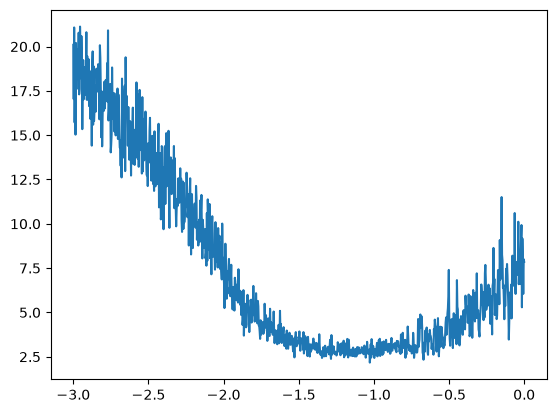

In [124]:
lri = []
lossi = []
for i in range(1000):

    # mini batch construction
    ix = torch.randint(0, X.shape[0], (32, )) # mini batch of size 32

    # forward pass
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])
    print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = lrs[i]
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    lri.append(lre[i])
    lossi.append(loss.item())
plt.plot(lri, lossi)

In [ ]:
# and now we know that the loss function is decreased efficiently with a 
# learning rate of about 0.1, which is the same as before

In [132]:
g = torch.Generator().manual_seed(2147483647)
c = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator = g)
W2 = torch.randn((100, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
n_para
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
for p in parameters:
    p.requires_grad = True

In [137]:
# lri = []
# lossi = []
for i in range(100000):

    # mini batch construction
    ix = torch.randint(0, X.shape[0], (32, )) # mini batch of size 32

    # forward pass
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])
    # print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    # lri.append(lre[i])
    # lossi.append(loss.item())
# plt.plot(lri, lossi)
print(loss.item())

# remember to decay the rate after a certain number of iternations

2.137667417526245


In [138]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @W2 + b2
loss = F.cross_entropy(logits, Y)
loss

tensor(2.2567, grad_fn=<NllLossBackward0>)

# getting serious

In [ ]:
# three split: training, dev/validation, and test (80%, 10%, 10%)
# dev can be used to find the best set of hyperparametere
# the test split is not very much used since when using the test split, 
# there is the risk of the model overfitting over the test split as well

In [ ]:
block_size = 3 
X, Y = [], [] 
for word in words:
    # print(word)
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '------>', itos[ix])
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y)

In [139]:
# build the dataset

def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1: n2])
Xts, Yts = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [147]:
g = torch.Generator().manual_seed(2147483647)
c = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator = g)
W2 = torch.randn((100, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
n_para

3481

In [148]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
for p in parameters:
    p.requires_grad = True

In [153]:
# lri = []
# lossi = []
for i in range(10000):

    # mini batch construction
    ix = torch.randint(0, Xtr.shape[0], (32, )) # mini batch of size 32

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    # lri.append(lre[i])
    # lossi.append(loss.item())
# plt.plot(lri, lossi)
print(loss.item())

# remember to decay the rate after a certain number of iternations

2.326841115951538


In [155]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3890, grad_fn=<NllLossBackward0>)

In [ ]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

# as you hopefully see, the loss function has a similar result on the training and validation set
# that is because the model is not powerful enough to be able to overfit, and we are on the stage of underfitting
# so from now on we try to power up the nn, i.e., add the number of parameters 

tensor(2.3826, grad_fn=<NllLossBackward0>)

In [159]:
g = torch.Generator().manual_seed(2147483647)
c = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 300), generator = g)
b1 = torch.randn(300, generator = g)
W2 = torch.randn((300, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
for p in parameters:
    p.requires_grad = True
n_para

10281

In [175]:
lossi = []
stepi = []
for i in range(30000):

    # mini batch construction
    ix = torch.randint(0, Xtr.shape[0], (32, )) # mini batch of size 32

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.item())
# plt.plot(lri, lossi)
# print(loss.item())

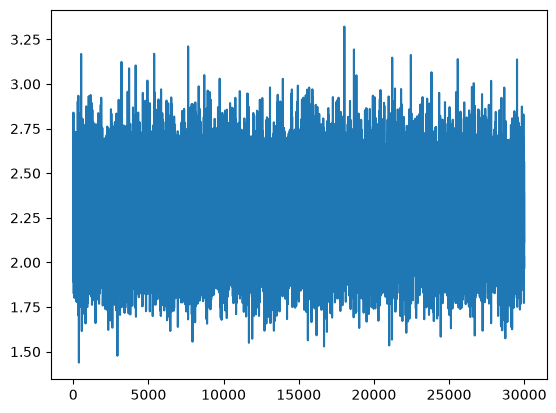

In [176]:
plt.plot(stepi, lossi)
# the relatively small size of the minibatch can create noise in the graph

In [177]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.2597, grad_fn=<NllLossBackward0>)

In [178]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2611, grad_fn=<NllLossBackward0>)

In [ ]:
# the problem now may be that the embedding vectors for the 27 chars are crammed into a 2D space
# if we increase the dimensions for the embedding, the model can be better at distinguishing them

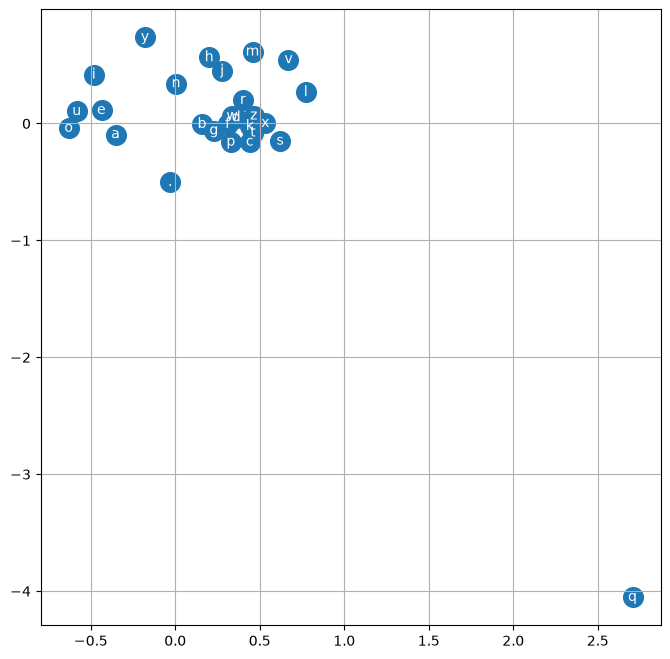

In [181]:
plt.figure(figsize = (8,8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha = 'center', va = 'center', color = 'white')
plt.grid('minor')

In [ ]:
# create 10-dimension embedding vectors for each char
# changing 300 to 200

In [193]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator = g) # this is now 30 = 10 * block_size
b1 = torch.randn(200, generator = g)
W2 = torch.randn((200, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
for p in parameters:
    p.requires_grad = True
n_para

11897

In [191]:
lossi = []
stepi = []

In [201]:
for i in range(50000):

    # mini batch construction
    ix = torch.randint(0, Xtr.shape[0], (32,)) # mini batch of size 32

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())
# plt.plot(lri, lossi)
# print(loss.item())

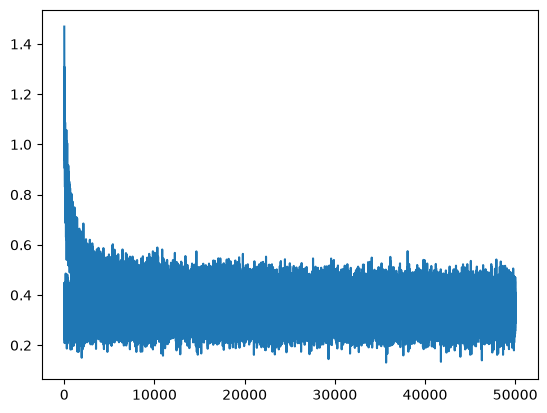

In [202]:
plt.plot(stepi, lossi)

In [203]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1794, grad_fn=<NllLossBackward0>)

In [204]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1993, grad_fn=<NllLossBackward0>)

In [206]:
# sample from the model

g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1, generator = g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))


carlah.
amerilli.
kimleige.
tyrencessa.
jazonte.
deliah.
jareei.
ner.
kentzeriiv.
kaleigh.
ham.
porriquint.
shous.
alian.
quin.
elo.
dearynix.
kaeliigs.
bon.
dedi.
